## LangGraph in One Minute

Think of LangGraph as a workflow builder for AI systems.

- `StateGraph` → **create** the graph
- `add_node()` → **add** a step
- `add_edge()` → **connect** steps
- `add_conditional_edges()` → **decide** which path to take
- `compile()` → **prepare** the graph
- `invoke()` → **run** the graph

### The core mental model

- **State** = information flowing through the system
- **Node** = an action or step
- **Edge** = a connection between steps
- **Graph** = the overall workflow
- **Agent** = an AI system that uses this workflow to reason and act

A LangGraph application combines:

1. data,
2. decisions,
3. model calls,
4. tools, and
5. loops.

That is what makes LangGraph useful for real agent systems—not just a single prompt.

In this notebook, we will start with a tiny graph and gradually add an LLM, conversation memory, and retrieval.


## The Office Analogy: LangGraph in Plain English

Picture an office where a **file folder** gets passed from desk to desk.

| Office | LangGraph | Code |
|---|---|---|
| The **folder**, which holds all the information | **State** | `MessagesState` or your own `TypedDict` |
| What sections the folder has | **State schema** | `class MyState(TypedDict): ...` |
| An **empty office**, with no desks yet | **Graph builder** | `graph = StateGraph(MessagesState)` |
| A **desk**, where someone reads the folder, does work and adds a page | **Node** | `graph.add_node("chatbot", chatbot)` |
| The **routing slip** ("desk A, then desk B") | **Edge** | `graph.add_edge("A", "B")` |
| A desk that decides where the folder goes next | **Conditional edge** | `graph.add_conditional_edges(...)` |
| Front door / exit | **START / END** | `START`, `END` |
| The office **opens for business** | **Compile** | `app = graph.compile()` |
| Drop a folder in the **inbox** | **Run** | `app.invoke({...})` |
| A **filing cabinet** that keeps folders between visits | **Checkpointer (memory)** | `MemorySaver()` |
| The **label** on a folder in the cabinet | **Thread ID** | `{"configurable": {"thread_id": "..."}}` |

### Two rules to remember

1. **A desk never rewrites the whole folder.** It hands back only the new pages, and LangGraph puts them into the folder.
2. **The folder's design decides how pages are added.** With `MessagesState`, new messages are **appended**, so the chat history only grows. With a plain field (for example `answer: str`), the new page **replaces** the old one.

### Build time vs. run time

```text
StateGraph(MessagesState)   → set up an empty office for chat-history folders   (build)
.add_node / .add_edge       → place desks and write the routing slip           (build)
.compile()                  → open the office                                  (build)
app.invoke({...})           → drop a folder in the inbox and watch it move     (run)
```

Nothing happens until `invoke()`. Everything before it is just setting up the office.

# LangGraph Overview

> Gain control with LangGraph to design agents that reliably handle complex tasks

Trusted by companies shaping the future of agents-- including Klarna, Replit, Elastic, and more-- LangGraph is a low-level orchestration framework and runtime for building, managing, and deploying long-running, stateful agents.

LangGraph is very low-level, and focused entirely on agent **orchestration**. Before using LangGraph, we recommend you familiarize yourself with some of the components used to build agents, starting with models and tools.

LangGraph is focused on the underlying capabilities important for agent orchestration: durable execution, streaming, human-in-the-loop, and more.

## Install

First, install the required packages:

In [1]:
# Install required packages (uncomment to run)
# !pip install -U langgraph langchain-openai langchain-community chromadb

## Setup

Load environment variables and configure OpenAI:

In [2]:
import os
from dotenv import load_dotenv

load_dotenv()

# Make sure OPENAI_API_KEY is set in your .env file
print("OpenAI API Key loaded:", "OPENAI_API_KEY" in os.environ)

OpenAI API Key loaded: True


---

# Part 1: Basic LangGraph with OpenAI

## Hello World Example

Let's create a simple hello world example to understand the basic structure of a LangGraph application:

> - **Objective:** See the smallest possible graph (one node) and how the folder (state) moves through it. No API call.
> - **Input:** `{"messages": [user: "hi!"]}`
> - **Flow:** `START → mock_llm → END`
> - **Output:** The full final state: the user message **plus** the appended AI message `"hello world"`.

In [2]:
from langgraph.graph import StateGraph, MessagesState, START, END

def mock_llm(state: MessagesState):
    return {"messages": [{"role": "ai", "content": "hello world"}]}

builder = StateGraph(MessagesState)      # the office plan (not runnable yet)
builder.add_node(mock_llm)
builder.add_edge(START, "mock_llm")
builder.add_edge("mock_llm", END)
mock_graph = builder.compile()          # the working office (runnable)

mock_result = mock_graph.invoke({"messages": [{"role": "user", "content": "hi!"}]})
print(mock_result)

{'messages': [HumanMessage(content='hi!', additional_kwargs={}, response_metadata={}, id='8e380cc6-5758-4c2e-bfce-1ab01c7220bb'), AIMessage(content='hello world', additional_kwargs={}, response_metadata={}, id='5943f17b-0327-45c2-b6b9-23ae60c27bb6', tool_calls=[], invalid_tool_calls=[])]}


### What just happened in the office?

**What is `MessagesState`?** It is a ready-made folder design that LangGraph provides. It has **one section, `messages`** (the chat history), and new messages are **appended** to it. You don't write it yourself; behind the scenes it looks like this:

```python
class MessagesState(TypedDict):
    messages: Annotated[list, add_messages]   # add_messages = "append, never overwrite"
```

**Syntax shortcut:** `builder.add_node(mock_llm)` has no name, so LangGraph uses the **function's name** (`"mock_llm"`) as the desk name. That's why the edges can refer to `"mock_llm"`.

**Following the folder, step by step:**

```text
1. invoke(...)       A folder arrives at the inbox:
                     [Human: "hi!"]

2. START → mock_llm  The folder goes to the mock_llm desk

3. mock_llm desk     Reads the folder, hands back ONE new page:
                     {"messages": [AI: "hello world"]}

4. LangGraph         APPENDS the page (MessagesState rule):
                     [Human: "hi!", AI: "hello world"]

5. mock_llm → END    The folder leaves the office

6. result            You get the WHOLE folder back, not just the last page
```

**What is the `id` on each message?** It is a unique **page number** stamped on every page in the folder. `add_messages` creates one automatically if the message doesn't have one.

- It is per **message**, not per `invoke()`. This run created 2 messages, so you see 2 ids.
- Without memory, every `invoke()` starts a new folder, so the ids change each run.
- `add_messages` uses the id to decide what to do: a **new** id is appended, an **existing** id **replaces** that page, and `RemoveMessage(id=...)` **deletes** it (useful for trimming long chat history).
- Not to be confused with `thread_id`, which identifies a **whole conversation** (you'll use it later with memory).

> **Try it:** print only the reply with `mock_result["messages"][-1].content`.

### Looking inside the folder

Run the cell below to see what is in the state: every page (message) in the folder, who wrote it, and its id. Then run the graph again with `stream()` to watch each desk add its page.

In [3]:
# 1. Everything in the final state (the whole folder)
print("State keys:", list(mock_result.keys()))
print("Number of messages:", len(mock_result["messages"]))
print()

# 2. Each page in the folder: who wrote it, what it says, its id
for i, msg in enumerate(mock_result["messages"]):
    print(f"{i}. {msg.type:<6} | {msg.content:<12} | id = {msg.id}")
print()

# 3. Readable view of the chat history
for msg in mock_result["messages"]:
    msg.pretty_print()

# 4. Step by step: what each desk (node) handed back
print()
print("--- Step by step (updates) ---")
for step in mock_graph.stream({"messages": [{"role": "user", "content": "hi!"}]},
                              stream_mode="updates"):
    print(step)

# 5. Step by step: the whole folder after each step
print()
print("--- Step by step (full state) ---")
for step in mock_graph.stream({"messages": [{"role": "user", "content": "hi!"}]},
                              stream_mode="values"):
    print([f"{m.type}: {m.content}" for m in step["messages"]])

State keys: ['messages']
Number of messages: 2

0. human  | hi!          | id = 8e380cc6-5758-4c2e-bfce-1ab01c7220bb
1. ai     | hello world  | id = 5943f17b-0327-45c2-b6b9-23ae60c27bb6

================================ Human Message =================================

hi!
================================== Ai Message ==================================

hello world

--- Step by step (updates) ---
{'mock_llm': {'messages': [{'role': 'ai', 'content': 'hello world'}]}}

--- Step by step (full state) ---
['human: hi!']
['human: hi!', 'ai: hello world']


## Using OpenAI as the LLM

Now let's replace the mock LLM with OpenAI's GPT model:

> - **Objective:** Same one-node graph, but the desk now calls a real LLM (OpenAI `gpt-4o-mini`).
> - **Input:** A user question in `{"messages": [...]}`
> - **Flow:** `START → llm → END`
> - **Output:** The final state; we print only the last message, which is the LLM's one-sentence answer.

In [4]:
from langgraph.graph import StateGraph, MessagesState, START, END
from langchain_openai import ChatOpenAI

# Initialize OpenAI LLM
llm = ChatOpenAI(model="gpt-4o-mini", temperature=0)

def call_llm(state: MessagesState):
    """Node that calls the OpenAI LLM."""
    response = llm.invoke(state["messages"])
    return {"messages": [response]}

# Build the graph
graph = StateGraph(MessagesState)
graph.add_node("llm", call_llm)
graph.add_edge(START, "llm")
graph.add_edge("llm", END)

# Compile
app = graph.compile()

# Test it
result = app.invoke({"messages": [{"role": "user", "content": "What is LangGraph in one sentence?"}]})
print(result["messages"][-1].content)

LangGraph is a framework designed to facilitate the development and deployment of applications that leverage language models and graph-based data structures for enhanced natural language processing tasks.


## Chatbot with Conversation History

LangGraph maintains state across invocations, making it perfect for chatbots:

## Memory, Checkpointer, and Config

A chatbot needs **memory** if we want it to remember information from earlier messages in the same conversation.

### Key Concepts

- **Memory**: The conversation information the chatbot can remember, such as the user's name, previous questions, and earlier messages.

- **Checkpointer**: Saves and loads the **graph state** so that previous conversation information can be retrieved later. In this example, `MemorySaver()` is used as the checkpointer.

- **Thread ID**: Identifies a specific conversation.
  - The **same `thread_id`** continues the same conversation.
  - A **different `thread_id`** starts a separate conversation.

- **Config**: Tells LangGraph which conversation/thread the current request belongs to.

### How Memory Works

The notebook configures a **checkpointer** and assigns a **thread ID** to the conversation.


### The Office Analogy: Adding a Filing Cabinet

**The problem:** without memory, every `invoke()` gets a **brand-new, empty folder**, and after the run the folder is **thrown away**. The LLM itself remembers nothing; it only knows what's in the folder it's shown. So if you ask "What's my name?" in a second call, the bot has never heard of Alice.

**The fix:** buy a **filing cabinet** and connect it to the office.

| Code | Office meaning |
|---|---|
| `memory = MemorySaver()` | Buy a filing cabinet (it lives in RAM) |
| `graph.compile(checkpointer=memory)` | Rule: **save the folder** in the cabinet after every run |
| `config = {"configurable": {"thread_id": "conversation-1"}}` | The **label** on the folder (one label per conversation or user) |
| `app.invoke(new_message, config)` | Find the folder with this label, add the new message, run, save it back |

**Following the folder across two calls:**

```text
CALL 1: "Hi! My name is Alice."   (label: conversation-1)
  1. Look in the cabinet for "conversation-1" → nothing yet, start an empty folder
  2. Append the new message        → [Human: Hi, I'm Alice]
  3. chatbot desk: LLM replies     → [Human: Hi, I'm Alice, AI: Hello Alice!]
  4. SAVE the folder in the cabinet

CALL 2: "What's my name?"          (same label: conversation-1)
  1. Look in the cabinet for "conversation-1" → FOUND the saved folder
  2. Append the new message        → [Human: Hi, I'm Alice, AI: Hello Alice!, Human: What's my name?]
  3. chatbot desk: LLM sees ALL 3 messages → "Your name is Alice!"
  4. SAVE the folder again (now 4 messages)
```

**Key points:**
- The second call only sends the **new** message. The cabinet supplies the rest of the history.
- The `chatbot` function is **the same** with or without memory. Only `compile(...)` and `invoke(..., config)` change.
- The LLM is **not learning**. LangGraph just resends the whole folder each time, so long conversations use more tokens and cost more.
- `MemorySaver` keeps the cabinet in RAM, so restarting the notebook erases it. In production, use `SqliteSaver` or `PostgresSaver` (same idea, but the cabinet is a database).

> - **Objective:** Give the chatbot **memory** (the filing cabinet) so it remembers earlier messages in the same conversation.
> - **Input:** Two separate `invoke()` calls, each with **one** new `HumanMessage`, plus the same `config` (`thread_id = "conversation-1"`).
> - **Flow:** Each call: load the folder from the cabinet → `START → chatbot → END` → save the folder.
> - **Output:** Call 1: a greeting. Call 2: the bot answers **"Alice"**, because the saved history was sent along with the question.

In [6]:
from langgraph.graph import StateGraph, MessagesState, START, END
from langgraph.checkpoint.memory import MemorySaver
from langchain_openai import ChatOpenAI
from langchain_core.messages import HumanMessage

llm = ChatOpenAI(model="gpt-4o-mini", temperature=0.7)

def chatbot(state: MessagesState):
    response = llm.invoke(state["messages"])
    return {"messages": [response]}

# Build graph with memory
graph = StateGraph(MessagesState)
graph.add_node("chatbot", chatbot)
graph.add_edge(START, "chatbot")
graph.add_edge("chatbot", END)

# Add memory checkpointer
memory = MemorySaver()
app = graph.compile(checkpointer=memory)

# Configuration with thread_id for conversation tracking
config = {"configurable": {"thread_id": "conversation-1"}}

# First message
response1 = app.invoke({"messages": [HumanMessage(content="Hi! My name is Alice.")]}, config)
print("Bot:", response1["messages"][-1].content)

# Second message - bot should remember the name
response2 = app.invoke({"messages": [HumanMessage(content="What's my name?")]}, config)
print("Bot:", response2["messages"][-1].content)

Bot: Hi Alice! How can I assist you today?
Bot: Your name is Alice. How can I help you today, Alice?


> - **Objective:** Show that memory belongs to a single `thread_id`, and look inside the cabinet.
> - **Input:** The same question with a **new** label (`conversation-2`), and the old `config`. Run the cell above first.
> - **Flow:** `invoke(..., config2)`, then `app.get_state(config)`.
> - **Output:** The bot does **not** know the name in conversation-2. Then all saved messages of conversation-1 are listed.

In [7]:
# Try it: a different label means a different folder, and the bot "forgets"
config2 = {"configurable": {"thread_id": "conversation-2"}}
response3 = app.invoke({"messages": [HumanMessage(content="What's my name?")]}, config2)
print("Bot (conversation-2):", response3["messages"][-1].content)

# Look inside the filing cabinet: what is saved in folder "conversation-1"?
print("\n--- Folder 'conversation-1' in the cabinet ---")
saved = app.get_state(config)
for m in saved.values["messages"]:
    print(f"{type(m).__name__:>12}: {m.content}")

Bot (conversation-2): I'm sorry, but I don't know your name. If you'd like to share it or if there's something else I can help you with, feel free to let me know!

--- Folder 'conversation-1' in the cabinet ---
HumanMessage: Hi! My name is Alice.
   AIMessage: Hi Alice! How can I assist you today?
HumanMessage: What's my name?
   AIMessage: Your name is Alice. How can I help you today, Alice?


---

# Part 2: RAG with LangGraph

Retrieval-Augmented Generation (RAG) combines document retrieval with LLM generation.

## Simple RAG Pipeline

### Office Analogy: Designing Your Own Folder

So far the folder had **one section** (`messages`). For RAG, we design a folder with **three sections**, and each desk fills in its own:

```text
RAGState folder
├── question  ← filled in by YOU at invoke()
├── context   ← filled in by the "retrieve" desk
└── answer    ← filled in by the "generate" desk
```

```text
invoke({"question": ...}) → [retrieve desk] adds context → [generate desk] adds answer → END
```

These sections have **no append rule** (no `add_messages`), so a desk's new page **replaces** whatever was in that section before.

> - **Objective:** **Setup only, no graph yet.** Design the RAG folder (`RAGState`) and build a small searchable knowledge base.
> - **Input:** 5 short documents about LangGraph.
> - **Flow:** Documents → embeddings (OpenAI API) → Chroma vector store → `retriever` that returns the top 2 matches.
> - **Output:** `"Vector store created with 5 documents"`, plus a `retriever` that the next cells use.

In [8]:
from typing import TypedDict, List
from langgraph.graph import StateGraph, START, END
from langchain_openai import ChatOpenAI, OpenAIEmbeddings
from langchain_community.vectorstores import Chroma
from langchain_core.documents import Document

# Define state for RAG
class RAGState(TypedDict):
    question: str
    context: List[Document]
    answer: str

# Initialize components
llm = ChatOpenAI(model="gpt-4o-mini", temperature=0)
embeddings = OpenAIEmbeddings()

# Create sample documents
documents = [
    Document(page_content="LangGraph is a library for building stateful, multi-actor applications with LLMs."),
    Document(page_content="LangGraph extends LangChain with cyclic graph capabilities for complex agent workflows."),
    Document(page_content="LangGraph supports persistence, streaming, and human-in-the-loop interactions."),
    Document(page_content="LangGraph uses nodes and edges to define the flow of data through an application."),
    Document(page_content="State in LangGraph is a shared data structure that gets updated as nodes execute."),
]

# Create vector store
vectorstore = Chroma.from_documents(documents, embeddings)
retriever = vectorstore.as_retriever(search_kwargs={"k": 2})

print("Vector store created with", len(documents), "documents")

C:\Users\Denish\AppData\Local\Temp\ipykernel_33416\2074150737.py:4: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.vectorstores import Chroma


Vector store created with 5 documents


> - **Objective:** A basic RAG pipeline: find relevant documents first, then answer **using** them.
> - **Input:** `{"question": "What is LangGraph used for?"}`
> - **Flow:** `START → retrieve → generate → END` (linear)
> - **Output:** The final state; we print `question` and `answer`. The answer is grounded in the retrieved documents.

In [9]:
# Define RAG nodes
def retrieve(state: RAGState):
    """Retrieve relevant documents."""
    docs = retriever.invoke(state["question"])
    return {"context": docs}

def generate(state: RAGState):
    """Generate answer using retrieved context."""
    context_text = "\n\n".join([doc.page_content for doc in state["context"]])
    
    prompt = f"""Answer the question based on the following context:

Context:
{context_text}

Question: {state["question"]}

Answer:"""
    
    response = llm.invoke(prompt)
    return {"answer": response.content}

# Build RAG graph
rag_graph = StateGraph(RAGState)
rag_graph.add_node("retrieve", retrieve)
rag_graph.add_node("generate", generate)

rag_graph.add_edge(START, "retrieve")
rag_graph.add_edge("retrieve", "generate")
rag_graph.add_edge("generate", END)

rag_app = rag_graph.compile()

# Test RAG
result = rag_app.invoke({"question": "What is LangGraph used for?"})
print("Question:", result["question"])
print("\nAnswer:", result["answer"])

Question: What is LangGraph used for?

Answer: LangGraph is used for building stateful, multi-actor applications with large language models (LLMs) and extends LangChain with cyclic graph capabilities for complex agent workflows.


## Advanced RAG with Query Rewriting

This example adds a query rewriting step to improve retrieval:

> - **Objective:** Improve retrieval by having the LLM **rewrite** the question before searching.
> - **Input:** `{"original_question": "How does state work?"}`
> - **Flow:** `START → rewrite → retrieve → generate → END` (linear, 3 desks)
> - **Output:** The original question, the rewritten question, and the final answer.
> - **Watch for:** In the saved output, the rewriter turned "state" into *political* state governance, because it didn't know the topic. The answer was still fine because the documents only cover LangGraph. Fix: tell the rewriter the domain ("in the context of LangGraph").

In [10]:
from typing import TypedDict, List
from langgraph.graph import StateGraph, START, END
from langchain_core.documents import Document

class AdvancedRAGState(TypedDict):
    original_question: str
    rewritten_question: str
    context: List[Document]
    answer: str

def rewrite_query(state: AdvancedRAGState):
    """Rewrite the query to be more specific for retrieval."""
    prompt = f"""Rewrite this question to be more specific and better suited for document retrieval.
Only output the rewritten question, nothing else.

Original question: {state["original_question"]}

Rewritten question:"""
    
    response = llm.invoke(prompt)
    return {"rewritten_question": response.content}

def retrieve_advanced(state: AdvancedRAGState):
    """Retrieve using rewritten query."""
    docs = retriever.invoke(state["rewritten_question"])
    return {"context": docs}

def generate_advanced(state: AdvancedRAGState):
    """Generate answer with context."""
    context_text = "\n\n".join([doc.page_content for doc in state["context"]])
    
    prompt = f"""Answer the question based on the context provided.

Context:
{context_text}

Original Question: {state["original_question"]}

Provide a helpful and concise answer:"""
    
    response = llm.invoke(prompt)
    return {"answer": response.content}

# Build advanced RAG graph
advanced_rag = StateGraph(AdvancedRAGState)
advanced_rag.add_node("rewrite", rewrite_query)
advanced_rag.add_node("retrieve", retrieve_advanced)
advanced_rag.add_node("generate", generate_advanced)

advanced_rag.add_edge(START, "rewrite")
advanced_rag.add_edge("rewrite", "retrieve")
advanced_rag.add_edge("retrieve", "generate")
advanced_rag.add_edge("generate", END)

advanced_rag_app = advanced_rag.compile()

# Test
result = advanced_rag_app.invoke({"original_question": "How does state work?"})
print("Original:", result["original_question"])
print("Rewritten:", result["rewritten_question"])
print("\nAnswer:", result["answer"])

Original: How does state work?
Rewritten: What are the mechanisms and functions of state governance in political systems?

Answer: In LangGraph, state is a shared data structure that is updated as different nodes execute within the application. Each node can read from and modify this state, allowing for dynamic interactions and coordination among multiple actors in the system. This enables the application to maintain a consistent and up-to-date representation of data throughout its execution.


> **What this cell does:** Installs `grandalf`, the small library that `draw_ascii()` needs to draw graphs as text.

In [11]:
! pip install grandalf

  Using cached grandalf-0.8-py3-none-any.whl.metadata (1.7 kB)
Using cached grandalf-0.8-py3-none-any.whl (41 kB)


> **What this cell does:** Draws the advanced RAG graph as plain text. Expect a straight line: `start → rewrite → retrieve → generate → end`.

In [12]:
print(advanced_rag_app.get_graph().draw_ascii())

+-----------+  
| __start__ |  
+-----------+  
      *        
      *        
      *        
 +---------+   
 | rewrite |   
 +---------+   
      *        
      *        
      *        
+----------+   
| retrieve |   
+----------+   
      *        
      *        
      *        
+----------+   
| generate |   
+----------+   
      *        
      *        
      *        
 +---------+   
 | __end__ |   
 +---------+   


> **What this cell does:** Draws the same graph as an image (Mermaid PNG). Needs an internet connection, because the image is rendered by an online service.

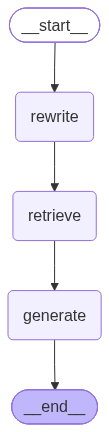

In [13]:
from IPython.display import Image, display
image= advanced_rag_app.get_graph().draw_mermaid_png()
display(Image(image))

> **What this cell does:** Shows the **entire** final folder from the advanced RAG run, all 4 sections: `original_question`, `rewritten_question`, `context` (the 2 retrieved documents), and `answer`. Use this to show students what the state looks like at the end.

In [14]:
result

{'original_question': 'How does state work?',
 'rewritten_question': 'What are the mechanisms and functions of state governance in political systems?',
 'context': [Document(metadata={}, page_content='LangGraph is a library for building stateful, multi-actor applications with LLMs.'),
  Document(metadata={}, page_content='State in LangGraph is a shared data structure that gets updated as nodes execute.')],
 'answer': 'In LangGraph, state is a shared data structure that is updated as different nodes execute within the application. Each node can read from and modify this state, allowing for dynamic interactions and coordination among multiple actors in the system. This enables the application to maintain a consistent and up-to-date representation of data throughout its execution.'}

## RAG with Relevance Check (Conditional Routing)

This example adds a node to check if retrieved documents are relevant, and routes accordingly:

> - **Objective:** RAG with a **quality gate**: check whether the retrieved documents are relevant before answering, and take a different path if they aren't.
> - **Input:** Two questions: one about LangGraph (relevant) and "What is the capital of France?" (not in the documents).
> - **Flow:** `START → retrieve → check →` **`generate`** *(if relevant)* **or** **`fallback`** *(if not)* `→ END`
> - **Output:** For each question: the relevance verdict and the answer. The fallback answer is prefixed with `(No relevant documents found)`.
> - **Watch for:** `add_conditional_edges("check", route_on_relevance)` has **no mapping dict**: the router returns node names directly, and the `Literal[...]` type hint tells LangGraph which paths exist (so the diagram can draw them).

In [15]:
from typing import TypedDict, List, Literal
from langgraph.graph import StateGraph, START, END
from langchain_core.documents import Document

class RAGWithCheckState(TypedDict):
    question: str
    context: List[Document]
    relevance: str  # "relevant" or "not_relevant"
    answer: str

def retrieve_docs(state: RAGWithCheckState):
    docs = retriever.invoke(state["question"])
    return {"context": docs}

def check_relevance(state: RAGWithCheckState):
    """Check if retrieved documents are relevant to the question."""
    context_text = "\n".join([doc.page_content for doc in state["context"]])
    
    prompt = f"""Determine if the following context is relevant to answer the question.
Answer only 'relevant' or 'not_relevant'.

Context: {context_text}

Question: {state["question"]}

Relevance:"""
    
    response = llm.invoke(prompt)
    relevance = "relevant" if "relevant" in response.content.lower() and "not" not in response.content.lower() else "not_relevant"
    return {"relevance": relevance}

def route_on_relevance(state: RAGWithCheckState) -> Literal["generate", "fallback"]:
    """Route based on relevance check."""
    if state["relevance"] == "relevant":
        return "generate"
    return "fallback"

def generate_with_context(state: RAGWithCheckState):
    context_text = "\n\n".join([doc.page_content for doc in state["context"]])
    prompt = f"""Answer based on the context:

Context: {context_text}

Question: {state["question"]}

Answer:"""
    response = llm.invoke(prompt)
    return {"answer": response.content}

def fallback_response(state: RAGWithCheckState):
    """Generate response without context when documents aren't relevant."""
    prompt = f"Answer this question to the best of your knowledge: {state['question']}"
    response = llm.invoke(prompt)
    return {"answer": f"(No relevant documents found) {response.content}"}

# Build graph with conditional routing
rag_check = StateGraph(RAGWithCheckState)
rag_check.add_node("retrieve", retrieve_docs)
rag_check.add_node("check", check_relevance)
rag_check.add_node("generate", generate_with_context)
rag_check.add_node("fallback", fallback_response)

rag_check.add_edge(START, "retrieve")
rag_check.add_edge("retrieve", "check")
rag_check.add_conditional_edges("check", route_on_relevance)
rag_check.add_edge("generate", END)
rag_check.add_edge("fallback", END)

rag_check_app = rag_check.compile()

# Test with relevant question
result1 = rag_check_app.invoke({"question": "What is LangGraph?"})
print("Q1:", result1["question"])
print("Relevance:", result1["relevance"])
print("Answer:", result1["answer"])

print("\n" + "="*50 + "\n")

# Test with unrelated question
result2 = rag_check_app.invoke({"question": "What is the capital of France?"})
print("Q2:", result2["question"])
print("Relevance:", result2["relevance"])
print("Answer:", result2["answer"])

Q1: What is LangGraph?
Relevance: relevant
Answer: LangGraph is a library designed to enhance LangChain by incorporating cyclic graph capabilities, enabling the development of stateful, multi-actor applications that utilize large language models (LLMs) for complex agent workflows.


Q2: What is the capital of France?
Relevance: not_relevant
Answer: (No relevant documents found) The capital of France is Paris.


> **What this cell does:** Draws the relevance-check graph. Expect `check` to **branch** into two arrows (`generate` and `fallback`) that both end at END.

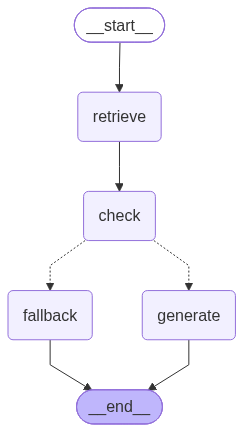

In [16]:
from IPython.display import Image, display
image= rag_check_app.get_graph().draw_mermaid_png()
display(Image(image))

---

# Part 3: Workflow Examples

LangGraph excels at building complex workflows with multiple steps, conditions, and loops.

## Linear Workflow: Content Processing Pipeline

> - **Objective:** A **linear** pipeline: several analysis steps run one after another, then the results are assembled into a report.
> - **Input:** `{"raw_text": sample_text}`, a paragraph about AI.
> - **Flow:** `START → summarize → keywords → sentiment → report → END`
> - **Output:** A formatted `final_report` with SUMMARY, KEYWORDS and SENTIMENT sections.
> - **Watch for:** The 3 analysis steps don't depend on each other, so they don't *need* to run in sequence. They could run in parallel (next example).

In [17]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END

class ContentState(TypedDict):
    raw_text: str
    summary: str
    keywords: str
    sentiment: str
    final_report: str

def summarize(state: ContentState):
    prompt = f"Summarize this text in 2 sentences:\n\n{state['raw_text']}"
    response = llm.invoke(prompt)
    return {"summary": response.content}

def extract_keywords(state: ContentState):
    prompt = f"Extract 5 key topics/keywords from this text as a comma-separated list:\n\n{state['raw_text']}"
    response = llm.invoke(prompt)
    return {"keywords": response.content}

def analyze_sentiment(state: ContentState):
    prompt = f"Analyze the sentiment of this text (positive/negative/neutral) and explain briefly:\n\n{state['raw_text']}"
    response = llm.invoke(prompt)
    return {"sentiment": response.content}

def create_report(state: ContentState):
    report = f"""=== CONTENT ANALYSIS REPORT ===

SUMMARY:
{state['summary']}

KEYWORDS:
{state['keywords']}

SENTIMENT:
{state['sentiment']}
"""
    return {"final_report": report}

# Build pipeline
pipeline = StateGraph(ContentState)
pipeline.add_node("summarize", summarize)
pipeline.add_node("keywords", extract_keywords)
pipeline.add_node("sentiment", analyze_sentiment)
pipeline.add_node("report", create_report)

pipeline.add_edge(START, "summarize")
pipeline.add_edge("summarize", "keywords")
pipeline.add_edge("keywords", "sentiment")
pipeline.add_edge("sentiment", "report")
pipeline.add_edge("report", END)

content_app = pipeline.compile()

# Test
sample_text = """
Artificial Intelligence is transforming industries worldwide. From healthcare diagnostics 
to autonomous vehicles, AI applications are becoming more sophisticated and widespread. 
However, concerns about job displacement and ethical implications continue to spark debate. 
Despite these challenges, investment in AI research continues to grow exponentially, 
with major tech companies leading the charge toward more advanced machine learning systems.
"""

result = content_app.invoke({"raw_text": sample_text})
print(result["final_report"])

=== CONTENT ANALYSIS REPORT ===

SUMMARY:
Artificial Intelligence is revolutionizing various industries, including healthcare and transportation, with increasingly advanced applications. While concerns about job displacement and ethical issues persist, investment in AI research is rapidly increasing, driven by major tech companies.

KEYWORDS:
Artificial Intelligence, healthcare diagnostics, autonomous vehicles, job displacement, machine learning systems

SENTIMENT:
The sentiment of the text is **neutral**. 

While it highlights the positive aspects of artificial intelligence, such as its transformative impact on industries and the growth of investment in AI research, it also acknowledges the negative concerns surrounding job displacement and ethical implications. The text presents a balanced view by discussing both the advancements and the challenges associated with AI, without leaning strongly towards a positive or negative sentiment overall.



> **What this cell does:** Draws the linear pipeline. Expect a straight vertical chain of 4 desks.

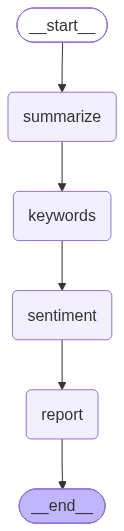

In [18]:
from IPython.display import Image, display
image= content_app.get_graph().draw_mermaid_png()
display(Image(image))

## Parallel Workflow: Multiple Analyses at Once

Run multiple independent tasks in parallel and combine results:

> - **Objective:** A **parallel** workflow: run independent tasks at the same time, then combine their results (fan-out → fan-in).
> - **Input:** `{"text": "Hello, how are you today?"}`
> - **Flow:** `START →` **`spanish` + `french` + `german`** *(at the same time)* `→ combine → END`
> - **Output:** One `combined` text with the original and all three translations.
> - **Watch for:** Each parallel desk writes its **own** key (`translation_spanish`, ...). If two parallel desks wrote the same key, LangGraph would raise an error.

In [19]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END

class ParallelState(TypedDict):
    text: str
    translation_spanish: str
    translation_french: str
    translation_german: str
    combined: str

def translate_spanish(state: ParallelState):
    prompt = f"Translate to Spanish:\n{state['text']}"
    response = llm.invoke(prompt)
    return {"translation_spanish": response.content}

def translate_french(state: ParallelState):
    prompt = f"Translate to French:\n{state['text']}"
    response = llm.invoke(prompt)
    return {"translation_french": response.content}

def translate_german(state: ParallelState):
    prompt = f"Translate to German:\n{state['text']}"
    response = llm.invoke(prompt)
    return {"translation_german": response.content}

def combine_translations(state: ParallelState):
    combined = f"""Original: {state['text']}

Spanish: {state['translation_spanish']}

French: {state['translation_french']}

German: {state['translation_german']}
"""
    return {"combined": combined}

# Build parallel graph
parallel_graph = StateGraph(ParallelState)
parallel_graph.add_node("spanish", translate_spanish)
parallel_graph.add_node("french", translate_french)
parallel_graph.add_node("german", translate_german)
parallel_graph.add_node("combine", combine_translations)

# Fan out to parallel nodes
parallel_graph.add_edge(START, "spanish")
parallel_graph.add_edge(START, "french")
parallel_graph.add_edge(START, "german")

# Fan in to combine
parallel_graph.add_edge("spanish", "combine")
parallel_graph.add_edge("french", "combine")
parallel_graph.add_edge("german", "combine")
parallel_graph.add_edge("combine", END)

parallel_app = parallel_graph.compile()

# Test
result = parallel_app.invoke({"text": "Hello, how are you today?"})
print(result["combined"])

Original: Hello, how are you today?

Spanish: Hola, ¿cómo estás hoy?

French: Bonjour, comment ça va aujourd'hui ?

German: Hallo, wie geht es dir heute?



> **What this cell does:** Draws the parallel graph. Expect START to **fan out** into 3 desks that **fan in** to `combine`.

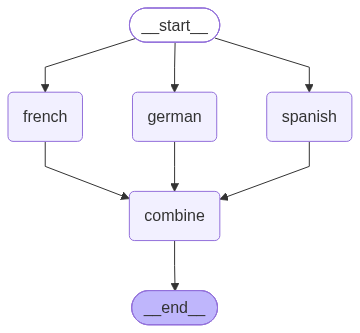

In [20]:
from IPython.display import Image, display
image= parallel_app.get_graph().draw_mermaid_png()
display(Image(image))

## Conditional Workflow: Routing Based on Classification

> - **Objective:** A **conditional (routing)** workflow: classify a support ticket, then send it to the right specialist.
> - **Input:** Three tickets, one at a time: a billing complaint, an app crash, and a business-hours question.
> - **Flow:** `START → classify → route_ticket →` **one of** `billing_handler` / `technical_handler` / `general_handler` `→ END`
> - **Output:** For each ticket: its `category` and a reply prefixed with the team name (e.g. `[BILLING TEAM]`).
> - **Watch for:** The `if category not in [...]` line is a **fallback**: an unexpected LLM answer goes to general support instead of breaking the routing.

In [21]:
from typing import TypedDict, Literal
from langgraph.graph import StateGraph, START, END

class TicketState(TypedDict):
    ticket: str
    category: str
    response: str

def classify_ticket(state: TicketState):
    """Classify the support ticket."""


    prompt = f"""Classify this support ticket into one of these categories:
- billing
- technical
- general

Only respond with the category name, nothing else.

Ticket: {state['ticket']}

Category:"""
    

    response = llm.invoke(prompt)
    category = response.content.strip().lower()
    if category not in ["billing", "technical", "general"]:
        category = "general"
    return {"category": category}

def route_ticket(state: TicketState) -> Literal["billing_handler", "technical_handler", "general_handler"]:
    """Route to appropriate handler."""
    if state["category"] == "billing":
        return "billing_handler"
    elif state["category"] == "technical":
        return "technical_handler"
    return "general_handler"

def handle_billing(state: TicketState):
    prompt = f"You are a billing support specialist. Help with this issue:\n{state['ticket']}"
    response = llm.invoke(prompt)
    return {"response": f"[BILLING TEAM] {response.content}"}

def handle_technical(state: TicketState):
    prompt = f"You are a technical support engineer. Help with this issue:\n{state['ticket']}"
    response = llm.invoke(prompt)
    return {"response": f"[TECHNICAL TEAM] {response.content}"}

def handle_general(state: TicketState):
    prompt = f"You are a customer support representative. Help with this inquiry:\n{state['ticket']}"
    response = llm.invoke(prompt)
    return {"response": f"[GENERAL SUPPORT] {response.content}"}

# Build routing graph
ticket_graph = StateGraph(TicketState)
ticket_graph.add_node("classify", classify_ticket)
ticket_graph.add_node("billing_handler", handle_billing)
ticket_graph.add_node("technical_handler", handle_technical)
ticket_graph.add_node("general_handler", handle_general)

ticket_graph.add_edge(START, "classify")
ticket_graph.add_conditional_edges("classify", route_ticket)
ticket_graph.add_edge("billing_handler", END)
ticket_graph.add_edge("technical_handler", END)
ticket_graph.add_edge("general_handler", END)

ticket_app = ticket_graph.compile()

# Test different ticket types
tickets = [
    "I was charged twice for my subscription this month!",
    "The app keeps crashing when I try to upload files.",
    "What are your business hours?"
]

for ticket in tickets:
    result = ticket_app.invoke({"ticket": ticket})
    print(f"Ticket: {ticket}")
    print(f"Category: {result['category']}")
    print(f"Response: {result['response'][:]}...\n")
    print("="*50 + "\n")

Ticket: I was charged twice for my subscription this month!
Category: billing
Response: [BILLING TEAM] I’m sorry to hear that you were charged twice for your subscription. Let’s work together to resolve this issue. Here are a few steps you can take:

1. **Check Your Payment History**: Log into your account and review your billing history to confirm the duplicate charges. Take note of the dates and amounts.

2. **Contact Customer Support**: Reach out to our customer support team directly. You can usually do this through the help section of our website or app. Provide them with the details of the duplicate charges, including your account information and any relevant transaction IDs.

3. **Request a Refund**: If the duplicate charge is confirmed, ask the support team to initiate a refund for the extra charge. They will guide you through the process.

4. **Monitor Your Account**: After the issue is resolved, keep an eye on your account to ensure that the refund is processed and that no fur

> **What this cell does:** Draws the routing graph. Expect `classify` to branch into **3** handler desks; only one of them runs per ticket.

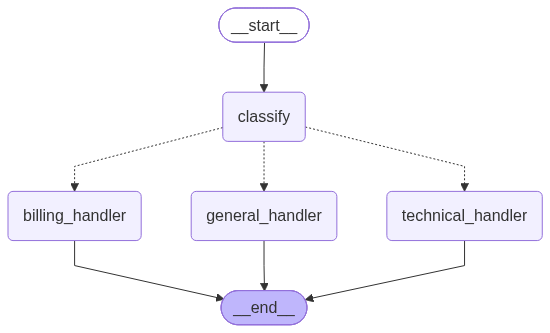

In [22]:
from IPython.display import Image, display
image= ticket_app.get_graph().draw_mermaid_png()
display(Image(image))

## Loop Workflow: Iterative Refinement

> - **Objective:** A **loop** workflow: write a draft, have it reviewed, and rewrite it until it's approved (writer ↔ editor).
> - **Input:** `{"topic": ..., "max_iterations": 3, "iteration": 0, "is_approved": False}`
> - **Flow:** `START → write → review →` **back to `write`** *(if not approved and under the limit)* **or** `END`
> - **Output:** The number of iterations, whether it was approved, and the final draft.
> - **Watch for:** `max_iterations` is the **safety brake**: without it, a reviewer that never approves would loop forever. In the saved output the reviewer approved on the first pass, so the loop ran only once. Also, the check `"APPROVED" in ...` would also match **"NOT APPROVED"**, which is a good example of fragile text parsing.

In [23]:
from typing import TypedDict, Literal
from langgraph.graph import StateGraph, START, END

class WritingState(TypedDict):
    topic: str
    draft: str
    feedback: str
    iteration: int
    max_iterations: int
    is_approved: bool

def write_draft(state: WritingState):
    """Write or rewrite the draft."""
    if state.get("draft"):
        prompt = f"""Improve this draft based on the feedback:

Current draft: {state['draft']}

Feedback: {state['feedback']}

Write an improved version:"""
    else:
        prompt = f"Write a short paragraph (3-4 sentences) about: {state['topic']}"
    
    response = llm.invoke(prompt)
    return {
        "draft": response.content,
        "iteration": state.get("iteration", 0) + 1
    }

def review_draft(state: WritingState):
    """Review and provide feedback."""
    prompt = f"""Review this draft and decide if it's good enough.
If it needs improvement, provide specific feedback.
If it's good, say 'APPROVED'.

Draft: {state['draft']}

Your review:"""
    
    response = llm.invoke(prompt)
    is_approved = "APPROVED" in response.content.upper()
    return {
        "feedback": response.content,
        "is_approved": is_approved
    }

def should_continue(state: WritingState) -> Literal["write", "__end__"]:
    """Decide whether to continue refining or finish."""
    if state["is_approved"]:
        return END
    if state["iteration"] >= state.get("max_iterations", 3):
        return END
    return "write"

# Build iterative graph
writing_graph = StateGraph(WritingState)
writing_graph.add_node("write", write_draft)
writing_graph.add_node("review", review_draft)

writing_graph.add_edge(START, "write")
writing_graph.add_edge("write", "review")
writing_graph.add_conditional_edges("review", should_continue)

writing_app = writing_graph.compile()

# Test
result = writing_app.invoke({
    "topic": "The benefits of morning exercise",
    "max_iterations": 3,
    "iteration": 0,
    "is_approved": False
})

print(f"Iterations: {result['iteration']}")
print(f"Approved: {result['is_approved']}")
print(f"\nFinal Draft:\n{result['draft']}")

Iterations: 1
Approved: True

Final Draft:
Morning exercise offers a multitude of benefits that can enhance both physical and mental well-being. Engaging in physical activity early in the day boosts metabolism, helping to burn calories more efficiently throughout the day. Additionally, morning workouts can improve mood and increase energy levels, setting a positive tone for the hours ahead. Establishing a consistent morning routine also fosters discipline and can lead to better overall health habits.


> **What this cell does:** Draws the loop graph. Expect an arrow from `review` going **back** to `write`; that cycle is what makes this a loop.

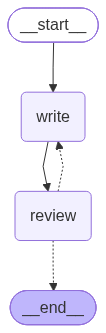

In [24]:
from IPython.display import Image, display
image= writing_app.get_graph().draw_mermaid_png()
display(Image(image))

## Agent with Tools

Create an agent that can use tools to complete tasks:

> - **Objective:** An **agent**: the LLM decides on its own whether it needs a tool (calculator, weather), uses it, and then answers.
> - **Input:** Three questions in `{"messages": [...]}`: a math question, a weather question, and one that needs **both** tools.
> - **Flow:** `START → agent →` **`tools`** *(if the LLM requested a tool)* `→ back to agent` … **or** `END` *(when it has a final answer)*
> - **Output:** The final natural-language answer, built from the tool results.
> - **Watch for:** This combines **conditional + loop**: the LLM itself decides the path. `eval()` in the calculator is fine for a demo but **unsafe** in production.

In [25]:
from typing import TypedDict, Annotated, Literal
from langgraph.graph import StateGraph, MessagesState, START, END
from langchain_openai import ChatOpenAI
from langchain_core.tools import tool
from langchain_core.messages import HumanMessage, ToolMessage

# Define tools
@tool
def calculator(expression: str) -> str:
    """Evaluate a mathematical expression. Use this for any math calculations."""
    try:
        result = eval(expression)
        return str(result)
    except Exception as e:
        return f"Error: {e}"

@tool
def get_weather(city: str) -> str:
    """Get the current weather for a city. Use this when asked about weather."""
    # Mock weather data
    weather_data = {
        "new york": "Sunny, 72°F",
        "london": "Cloudy, 58°F",
        "tokyo": "Rainy, 65°F",
        "paris": "Partly cloudy, 68°F"
    }
    return weather_data.get(city.lower(), f"Weather data not available for {city}")

# Create LLM with tools
tools = [calculator, get_weather]
llm_with_tools = ChatOpenAI(model="gpt-4o-mini", temperature=0).bind_tools(tools)

def agent(state: MessagesState):
    """Call the LLM with tools."""
    response = llm_with_tools.invoke(state["messages"])
    return {"messages": [response]}

def tool_executor(state: MessagesState):
    """Execute tool calls."""
    last_message = state["messages"][-1]
    tool_results = []
    
    for tool_call in last_message.tool_calls:
        tool_name = tool_call["name"]
        tool_args = tool_call["args"]
        
        if tool_name == "calculator":
            result = calculator.invoke(tool_args)
        elif tool_name == "get_weather":
            result = get_weather.invoke(tool_args)
        else:
            result = f"Unknown tool: {tool_name}"
        
        tool_results.append(
            ToolMessage(content=result, tool_call_id=tool_call["id"])
        )
    
    return {"messages": tool_results}

def should_use_tools(state: MessagesState) -> Literal["tools", "__end__"]:
    """Check if the LLM wants to use tools."""
    last_message = state["messages"][-1]
    if hasattr(last_message, "tool_calls") and last_message.tool_calls:
        return "tools"
    return END

# Build agent graph
agent_graph = StateGraph(MessagesState)
agent_graph.add_node("agent", agent)
agent_graph.add_node("tools", tool_executor)

agent_graph.add_edge(START, "agent")
agent_graph.add_conditional_edges("agent", should_use_tools)
agent_graph.add_edge("tools", "agent")  # Loop back after tool execution

agent_app = agent_graph.compile()

# Test the agent
print("Test 1: Math question")
result = agent_app.invoke({"messages": [HumanMessage(content="What is 25 * 17 + 83?")]})
print(result["messages"][-1].content)

print("\nTest 2: Weather question")
result = agent_app.invoke({"messages": [HumanMessage(content="What's the weather in Tokyo?")]})
print(result["messages"][-1].content)

print("\nTest 3: Combined question")
result = agent_app.invoke({"messages": [HumanMessage(content="What's the weather in London and also calculate 100/4?")]})
print(result["messages"][-1].content)

Test 1: Math question
The result of \( 25 \times 17 + 83 \) is 508.

Test 2: Weather question
The weather in Tokyo is rainy with a temperature of 65°F.

Test 3: Combined question
The weather in London is currently cloudy with a temperature of 58°F. Additionally, the result of the calculation \(100 \div 4\) is 25.0.


> **What this cell does:** Draws the agent graph. Expect `agent` with a dotted branch to `tools` and an arrow from `tools` **back** to `agent`.

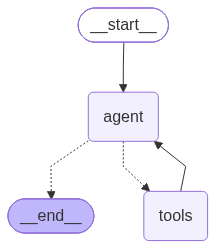

In [26]:
from IPython.display import Image, display
image= agent_app.get_graph().draw_mermaid_png()
display(Image(image))

---

## Core Benefits Summary

LangGraph provides low-level supporting infrastructure for *any* long-running, stateful workflow or agent:

* **Durable execution**: Build agents that persist through failures and can run for extended periods
* **Human-in-the-loop**: Incorporate human oversight by inspecting and modifying agent state at any point
* **Comprehensive memory**: Create stateful agents with both short-term and long-term memory
* **Debugging with LangSmith**: Gain deep visibility into complex agent behavior
* **Production-ready deployment**: Deploy sophisticated agent systems with scalable infrastructure

---

**Documentation**: https://docs.langchain.com/llms.txt